# WWV/H Signal Synthesis

This is a Python port of the original MATLAB code used to create the WWV/H test signal. [![DOI](https://zenodo.org/badge/DOI/10.5281/zenodo.5182323.svg)](https://doi.org/10.5281/zenodo.5182323)

## First Test Signal
This is a Python port of the original MATLAB code used to create the WWV/H test signal. [![DOI](https://zenodo.org/badge/DOI/10.5281/zenodo.5182323.svg)](https://doi.org/10.5281/zenodo.5182323)

White noise: 2.0000 seconds.
Coherent tones: 10.0000 seconds.
The chirps take 8.0000 seconds total.
Pulses: 2.0000 seconds.
Voice clip: 10.0000 seconds.
Total length: 41.0000 seconds.


/tmp/ipykernel_17514/80712940.py:136: WavFileWarning: Chunk (non-data) not understood, skipping it.
  v_rate, voice_audio = wavfile.read("voiceintro.wav")


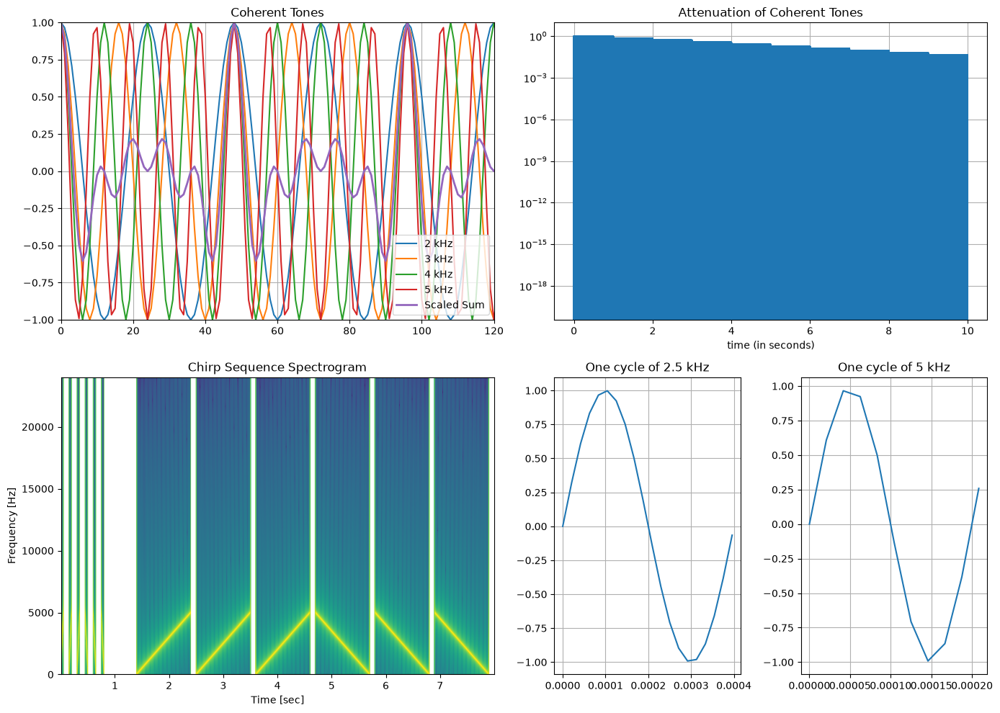

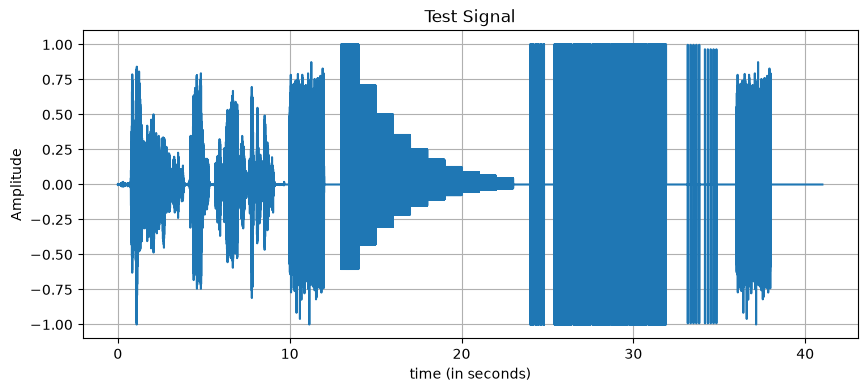

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

# Optional playback library: pip install sounddevice
try:
    import sounddevice as sd
    HAS_SOUNDDEVICE = True
except ImportError:
    HAS_SOUNDDEVICE = False

# -----------------------------------------------------------------------------
# Housekeeping & Reproducibility
# -----------------------------------------------------------------------------
np.random.seed(0)  # Reset RNG to reproduce default seed behavior

# Time specifications:
Fs = 48000                   # samples per second
dt = 1.0 / Fs                # seconds per sample
StopTime = 2.0               # seconds
t = np.arange(0, StopTime, dt)

# -----------------------------------------------------------------------------
# 1. White Noise Generation
# -----------------------------------------------------------------------------
# wgn(m, 1, 0) in MATLAB generates Gaussian noise of 0 dBW (power=1, std=1)
y1 = np.random.normal(0, 1, int(Fs * StopTime))
y1 = y1 / np.max(np.abs(y1))  # Normalize to prevent clipping
print(f"White noise: {len(y1) / Fs:.4f} seconds.")

# -----------------------------------------------------------------------------
# 2. Phase-Locked Audio Tones & Attenuation Loop
# -----------------------------------------------------------------------------
t_1s = np.arange(0, 1.0, dt)  # 1 second vector

y2a = np.cos(2 * np.pi * 2000 * t_1s)  # 2 kHz
y2b = np.cos(2 * np.pi * 3000 * t_1s)  # 3 kHz
y2c = np.cos(2 * np.pi * 4000 * t_1s)  # 4 kHz
y2d = np.cos(2 * np.pi * 5000 * t_1s)  # 5 kHz

y2_tones = 0.25 * (y2a + y2b + y2c + y2d)  # Avoid clipping

# Attenuate by ~3 dB per step (9 iterations)
y2 = y2_tones.copy()
y_prev = y2_tones.copy()
for _ in range(9):
    y_attenuated = (1.0 / np.sqrt(2)) * y_prev
    y_prev = y_attenuated
    y2 = np.concatenate([y2, y_attenuated])

print(f"Coherent tones: {len(y2) / Fs:.4f} seconds.")

# -----------------------------------------------------------------------------
# 3. Chirp Signal Sequence
# -----------------------------------------------------------------------------
longchirp = 1.0  # 1 second
t2 = np.arange(0, longchirp, dt)
y3 = signal.chirp(t2, f0=0, t1=longchirp, f1=5000, method='linear')  # Up
y4 = signal.chirp(t2, f0=5000, t1=longchirp, f1=0, method='linear')  # Down

shortchirp = 0.05  # 0.05 second
t3 = np.arange(0, shortchirp, dt)
y5 = signal.chirp(t3, f0=0, t1=shortchirp, f1=5000, method='linear') # Up
y6 = signal.chirp(t3, f0=5000, t1=shortchirp, f1=0, method='linear') # Down

z_01 = np.zeros(int(0.1 * Fs))  # 0.1s blank gap
z_05 = np.zeros(int(0.5 * Fs))  # 0.5s blank gap

short_up = np.concatenate([y5, z_01, y5, z_01, y5, z_01])
short_down = np.concatenate([y6, z_01, y6, z_01, y6, z_01])
long_up = np.concatenate([y3, z_01, y3, z_01, y3, z_01])
long_down = np.concatenate([y4, z_01, y4, z_01, y4, z_01])

chirps = np.concatenate([short_up, short_down, z_05, long_up, long_down])

# Pad to end on an even full second
rem = len(chirps) % Fs
if rem != 0:
    pad_samples = Fs - rem
    print(f"Adding {pad_samples / Fs:.4f} seconds of blank time to end on an even second...")
    chirps = np.concatenate([chirps, np.zeros(pad_samples)])

print(f"The chirps take {len(chirps) / Fs:.4f} seconds total.")

# -----------------------------------------------------------------------------
# 4. Spike / Single-Cycle Pulses (2.5 kHz and 5 kHz)
# -----------------------------------------------------------------------------
# 2.5 kHz single cycle pulse
t4 = np.arange(0, 1 / 2500 + dt / 2, dt)
spike2k5 = np.sin(2 * np.pi * 2500 * t4)
y7 = np.zeros(Fs)
spikecount = 6
step = Fs // spikecount

for n in range(step, Fs - len(spike2k5) + 1, step):
    idx = n - 1  # 0-based index adjustment for MATLAB 1-based indexing
    y7[idx : idx + len(spike2k5)] = spike2k5

# 5 kHz single cycle pulse
t5 = np.arange(0, 1 / 5000 + dt / 2, dt)
spike5k = np.sin(2 * np.pi * 5000 * t5)
y7b = np.zeros(Fs)

for n in range(step, Fs - len(spike5k) + 1, step):
    idx = n - 1
    y7b[idx : idx + len(spike5k)] = spike5k

# Append 2.5 kHz and 5 kHz pulse seconds
y7 = np.concatenate([y7, y7b])
print(f"Pulses: {len(y7) / Fs:.4f} seconds.")

# -----------------------------------------------------------------------------
# 5. Compile Main Waveform
# -----------------------------------------------------------------------------
z_1s = np.zeros(Fs)
y = np.concatenate([
    y1, z_1s,
    y2, z_1s,
    chirps, z_1s,
    y7, z_1s,
    y1, np.zeros(3 * Fs)
])

# Save sequence without voice intro
wavfile.write("test-without-voice.wav", Fs, y.astype(np.float32))

# -----------------------------------------------------------------------------
# 6. Optional Voice Clip Prepending
# -----------------------------------------------------------------------------
voice = np.zeros(Fs * 10)  # Preallocate 10 seconds

if os.path.exists("voiceintro.wav"):
    v_rate, voice_audio = wavfile.read("voiceintro.wav")
    # Convert stereo to mono if needed
    if voice_audio.ndim > 1:
        voice_audio = voice_audio[:, 0]

    # Cast to float in range [-1, 1] if integer format
    if voice_audio.dtype == np.int16:
        voice_audio = voice_audio / 32768.0
    elif voice_audio.dtype == np.int32:
        voice_audio = voice_audio / 2147483648.0

    length = min(len(voice_audio), len(voice))
    voice[:length] = voice_audio[:length]
    voice = voice / np.max(np.abs(voice))
else:
    print("Notice: 'voiceintro.wav' not found, using silence for voice intro section.")

y = np.concatenate([voice, y])
print(f"Voice clip: {len(voice) / Fs:.4f} seconds.")
print(f"Total length: {len(y) / Fs:.4f} seconds.")

# -----------------------------------------------------------------------------
# 7. Visualization & Plotting
# -----------------------------------------------------------------------------
fig = plt.figure(figsize=(14, 10))
gs = fig.add_gridspec(2, 4)

# Subplot 1: Coherent Tones Waveform Zoom
ax1 = fig.add_subplot(gs[0, :2])
ax1.plot(y2a, label='2 kHz')
ax1.plot(y2b, label='3 kHz')
ax1.plot(y2c, label='4 kHz')
ax1.plot(y2d, label='5 kHz')
ax1.plot(y2[:len(y2a)], label='Scaled Sum', linewidth=2)
ax1.set_xlim([0, 120])
ax1.set_ylim([-1, 1])
ax1.set_title('Coherent Tones')
ax1.legend()
ax1.grid(True)

# Subplot 2: Semilogy Attenuation Plot
ax2 = fig.add_subplot(gs[0, 2:])
time_y2 = np.arange(0, len(y2) * dt, dt)
ax2.semilogy(time_y2, np.abs(y2))
ax2.set_xlabel('time (in seconds)')
ax2.set_title('Attenuation of Coherent Tones')
ax2.grid(True)

# Subplot 3: Spectrogram of Chirp Sequence
ax3 = fig.add_subplot(gs[1, :2])
ax3.specgram(chirps, Fs=Fs, NFFT=1024, noverlap=512)
ax3.set_title('Chirp Sequence Spectrogram')
ax3.set_xlabel('Time [sec]')
ax3.set_ylabel('Frequency [Hz]')

# Subplot 4: One cycle of 2.5 kHz
ax4 = fig.add_subplot(gs[1, 2])
ax4.plot(t4, spike2k5)
ax4.set_title('One cycle of 2.5 kHz')
ax4.grid(True)

# Subplot 5: One cycle of 5 kHz
ax5 = fig.add_subplot(gs[1, 3])
ax5.plot(t5, spike5k)
ax5.set_title('One cycle of 5 kHz')
ax5.grid(True)

plt.tight_layout()

# Figure 2: Full Signal vs Time
plt.figure(figsize=(10, 4))
time_full = np.arange(0, len(y) * dt, dt)
plt.plot(time_full, y)
plt.xlabel('time (in seconds)')
plt.ylabel('Amplitude')
plt.title('Test Signal')
plt.grid(True)

plt.show()

# -----------------------------------------------------------------------------
# 8. Export Files & Play Audio
# -----------------------------------------------------------------------------
# Save to WAV (float32 natively supported by Scipy)
wavfile.write("test.wav", Fs, y.astype(np.float32))

# Save to CSV
np.savetxt("test.csv", y, delimiter=",")

# Play Audio
#
# if HAS_SOUNDDEVICE:
#     print("Playing test audio clip...")
#     sd.play(y, Fs)
#     sd.wait()
# else:
#     print("Install 'sounddevice' module (`pip install sounddevice`) to enable audio playback.")
display(Audio(y, rate=Fs))

In [4]:
import numpy as np
from scipy.io import wavfile
from IPython.display import Audio, display

def synthesize_wwv_minute(station='WWV', Fs=48000, duration_sec=60):
    """
    Synthesizes a 60-second standard WWV or WWVH background minute.
    - WWV: 1000 Hz ticks + 1000 Hz minute marker
    - WWVH: 1200 Hz ticks + 1200 Hz minute marker
    - BCD 100 Hz subcarrier timecode on both
    """
    total_samples = int(Fs * duration_sec)
    bg = np.zeros(total_samples, dtype=np.float32)
    dt = 1.0 / Fs

    # Tick frequency: 1000 Hz for WWV, 1200 Hz for WWVH
    tick_freq = 1000.0 if station.upper() == 'WWV' else 1200.0

    # -------------------------------------------------------------------------
    # 1. Ticks and Minute Marker Pulse
    # -------------------------------------------------------------------------
    for sec in range(min(60, duration_sec)):
        sec_start = sec * Fs

        if sec == 0:
            # Second 0: 800 ms Minute Marker tone
            t_mark = np.arange(0, 0.8, dt)
            tone = 0.5 * np.sin(2 * np.pi * tick_freq * t_mark)
            bg[sec_start : sec_start + len(tone)] += tone

        elif sec in (29, 59):
            # Seconds 29 & 59: Tick is omitted
            pass

        else:
            # 5 ms tick burst (5 cycles @ 1000 Hz, 6 cycles @ 1200 Hz)
            t_tick = np.arange(0, 0.005, dt)
            tick = 0.5 * np.sin(2 * np.pi * tick_freq * t_tick)
            bg[sec_start : sec_start + len(tick)] += tick

    # -------------------------------------------------------------------------
    # 2. 100 Hz BCD Timecode Subcarrier
    # -------------------------------------------------------------------------
    marker_seconds = {0, 9, 19, 29, 39, 49, 59}

    for sec in range(min(60, duration_sec)):
        sec_start = sec * Fs
        tc_start = sec_start + int(0.030 * Fs)  # Starts 30 ms into the second

        # BCD pulse width encoding
        if sec in marker_seconds:
            pw = 0.770  # Position Marker 'P' (770 ms)
        elif (sec % 2) == 1:
            pw = 0.470  # Bit 1 (470 ms)
        else:
            pw = 0.170  # Bit 0 (170 ms)

        t_tc = np.arange(0, pw, dt)
        bcd_tone = 0.2 * np.sin(2 * np.pi * 100.0 * t_tc)  # 100 Hz subcarrier

        end_idx = min(tc_start + len(bcd_tone), total_samples)
        valid_len = end_idx - tc_start
        if valid_len > 0:
            bg[tc_start : end_idx] += bcd_tone[:valid_len]

    return bg


def overlay_and_save(bg_track, test_signal, filename, Fs=48000):
    """Mixes the background minute track with the SciMod test signal and normalizes."""
    mixed = bg_track.copy()
    sig_len = min(len(test_signal), len(mixed))

    # Mix background + test signal payload
    mixed[:sig_len] += test_signal[:sig_len]

    # Peak normalize to -1 dB (0.89) to avoid clipping
    peak = np.max(np.abs(mixed))
    if peak > 0:
        mixed = (mixed / peak) * 0.89

    wavfile.write(filename, Fs, mixed.astype(np.float32))
    return mixed


# -----------------------------------------------------------------------------
# Generate Background Tracks & Overlay Test Signal `y`
# -----------------------------------------------------------------------------
# Generate 60-second minute background tracks
wwv_bg = synthesize_wwv_minute(station='WWV', Fs=Fs, duration_sec=60)
wwvh_bg = synthesize_wwv_minute(station='WWVH', Fs=Fs, duration_sec=60)

# Mix with `y` (from the previous script)
wwv_min8 = overlay_and_save(wwv_bg, y, "wwv_minute8.wav", Fs=Fs)
wwvh_min48 = overlay_and_save(wwvh_bg, y, "wwvh_minute48.wav", Fs=Fs)

# -----------------------------------------------------------------------------
# Inline Jupyter Audio Players
# -----------------------------------------------------------------------------
print("WWV Minute 8 (1000 Hz Ticks + SciMod Test Signal):")
display(Audio(data=wwv_min8, rate=Fs))

print("WWVH Minute 48 (1200 Hz Ticks + SciMod Test Signal):")
display(Audio(data=wwvh_min48, rate=Fs))

WWV Minute 8 (1000 Hz Ticks + SciMod Test Signal):


WWVH Minute 48 (1200 Hz Ticks + SciMod Test Signal):


## Bob Signal Proposal
Repeated 511-bit maximum length sequence (MLS) (80 repetitions, 6.8 sec duration)

In [6]:
import numpy as np
from scipy.signal import max_len_seq, butter, filtfilt

def generate_mls_sequence(m=9, duration_sec=6.8, Fs=48000, carrier_freq=0.0, amplitude=0.5):
    """
    Generates a 511-bit Maximum Length Sequence (MLS).
    
    Parameters:
    - m: LFSR order (m=9 yields 2^9 - 1 = 511 bits).
    - duration_sec: Target duration in seconds (6.8 s).
    - Fs: Sampling rate (48000 Hz).
    - carrier_freq: Audio carrier frequency in Hz for BPSK modulation (0.0 for baseband).
    - amplitude: Peak amplitude scaling.
    """
    # 1. Generate order-9 m-sequence (511 bits of 0 and 1)
    mls_bits, _ = max_len_seq(m)
    
    # 2. Convert to antipodal bipolar signal (0 -> -1.0, 1 -> +1.0)
    bipolar_mls = 2.0 * mls_bits - 1.0
    
    # 3. Stretch sequence across target duration (326,400 samples @ 48 kHz)
    total_samples = int(duration_sec * Fs)
    chip_indices = np.floor(np.linspace(0, len(bipolar_mls), total_samples, endpoint=False)).astype(int)
    baseband_mls = bipolar_mls[chip_indices]
    
    # 4. Optional BPSK Carrier Modulation (Phase shift 0 / pi)
    if carrier_freq > 0:
        t = np.arange(total_samples) / Fs
        carrier = np.cos(2 * np.pi * carrier_freq * t)
        mls_signal = amplitude * baseband_mls * carrier
    else:
        mls_signal = amplitude * baseband_mls
        
    return mls_signal.astype(np.float32)

# Generate 511-bit MLS (Baseband or BPSK-modulated)
Fs = 48000
mls_baseband = generate_mls_sequence(m=9, duration_sec=6.8, Fs=Fs, carrier_freq=0.0)
mls_bpsk = generate_mls_sequence(m=9, duration_sec=6.8, Fs=Fs, carrier_freq=2500.0)  # 2.5 kHz BPSK

# Append to main WWV waveform y:
# y_total = np.concatenate([y, np.zeros(Fs), mls_bpsk, np.zeros(Fs)])
print(f"Generated 511-bit MLS: {len(mls_bpsk) / Fs:.4f} seconds ({len(mls_bpsk)} samples).")
display(Audio(data=mls_bpsk, rate=Fs))

Generated 511-bit MLS: 6.8000 seconds (326400 samples).


## MITRE Signal Proposal (Jay)



|     | Current Schedule |           |   | New Schedule |          |                        |   |                              |
|-----|------------------|-----------|---|--------------|----------|------------------------|---|------------------------------|
|     | Duration         |           |   |              | Duration |                        |   |                              |
| 0   | 00:10.0          | Voice     |   | 0            | 00:10.0  | Voice                  |   |                              |
| :10 | 00:02.0          | AWGN      |   | :10          | 00:12.8  | ML 256 Pulse, 0.05 IPP |   |                              |
| :12 | 00:01.0          | Blank     |   | :23          | 00:01.2  | Blank                  |   |                              |
| :13 | 00:10.0          | Sines     |   | :24          | 00:10.2  | LFM Pulse Train        |   | PRF = 25 BW = 6 kHz NP = 256 |
| :23 | 00:01.0          | Blank     |   | :34          | 00:00.8  | Blank                  |   |                              |
| :24 | 00:08.0          | LFMs      |   | :35          | 00:06.0  | Other                  |   |                              |
| :32 | 00:02.0          | Blank     |   | :41          |          |                        |   |                              |
| :34 | 00:01.0          | One Cycle |   |              |          |                        |   |                              |
| :35 | 00:01.0          | Blank     |   |              |          |                        |   |                              |
| :36 | 00:02.0          | AWGN      |   |              |          |                        |   |                              |
| :38 | 00:03.0          | Blank     |   |              |          |                        |   |                              |
| :41 |                  |           |   |              |          |                        |   |                              |

/tmp/ipykernel_17514/714504284.py:22: WavFileWarning: Chunk (non-data) not understood, skipping it.
  v_rate, voice_audio = wavfile.read("voiceintro.wav")


Voice segment: 10.00 seconds.
ML Pulse train: 12.80 seconds (256 pulses @ 50 ms IPP).
LFM Pulse train: 10.24 seconds (256 chirps @ PRF=25 Hz, BW=6 kHz).
Other (MLS sequence): 6.00 seconds.
Total sequence length: 41.00 seconds.


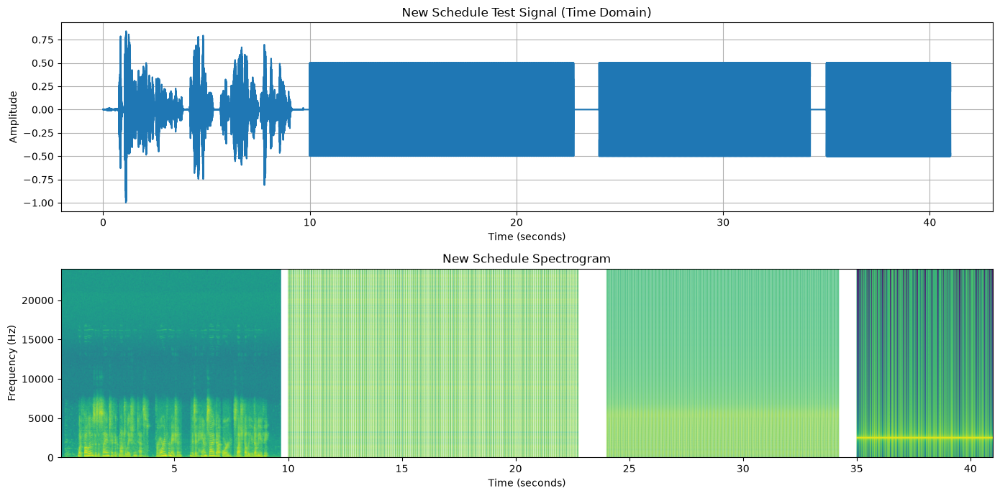

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import Audio, display

# -----------------------------------------------------------------------------
# Setup & Constants
# -----------------------------------------------------------------------------
Fs = 48000                  # Samples per second
dt = 1.0 / Fs               # Seconds per sample
np.random.seed(0)           # Reproducible random seed

# =============================================================================
# 1. Voice Preallocation (00:00 - 00:10.0 | 10.0s)
# =============================================================================
voice_duration = 10.0
voice = np.zeros(int(Fs * voice_duration), dtype=np.float32)

if os.path.exists("voiceintro.wav"):
    v_rate, voice_audio = wavfile.read("voiceintro.wav")
    if voice_audio.ndim > 1:
        voice_audio = voice_audio[:, 0]
    if voice_audio.dtype == np.int16:
        voice_audio = voice_audio / 32768.0
    elif voice_audio.dtype == np.int32:
        voice_audio = voice_audio / 2147483648.0
        
    length = min(len(voice_audio), len(voice))
    voice[:length] = voice_audio[:length]
    voice = voice / np.max(np.abs(voice))

print(f"Voice segment: {len(voice)/Fs:.2f} seconds.")

# =============================================================================
# 2. ML 256 Pulse, 0.05 IPP (00:10.0 - 00:22.8 | 12.8s)
# =============================================================================
np_ml = 256                         # 256 pulses
ipp_ml_sec = 0.05                   # Inter-pulse period = 50 ms
samples_per_ipp_ml = int(Fs * ipp_ml_sec)
pulse_dur_ml = 0.010                # 10 ms pulse duration per IPP

# Generate base 511-bit MLS BPSK pulse
mls_bits, _ = signal.max_len_seq(9) # Order-9 m-sequence (511 bits)
mls_bipolar = 2.0 * mls_bits - 1.0

t_p = np.arange(0, pulse_dur_ml, dt)
chip_idx = np.floor(np.linspace(0, len(mls_bipolar), len(t_p), endpoint=False)).astype(int)
single_ml_pulse = 0.5 * mls_bipolar[chip_idx] * np.cos(2 * np.pi * 2500 * t_p)

# Tile 256 pulses into the 12.8-second window
ml_sequence = np.zeros(np_ml * samples_per_ipp_ml, dtype=np.float32)
for i in range(np_ml):
    idx_start = i * samples_per_ipp_ml
    ml_sequence[idx_start : idx_start + len(single_ml_pulse)] = single_ml_pulse

print(f"ML Pulse train: {len(ml_sequence)/Fs:.2f} seconds (256 pulses @ 50 ms IPP).")

# =============================================================================
# 3. Blank Period 1 (00:22.8 - 00:24.0 | 1.2s)
# =============================================================================
blank1 = np.zeros(int(Fs * 1.2), dtype=np.float32)

# =============================================================================
# 4. LFM Pulse Train (00:24.0 - 00:34.24 | 10.24s)
# PRF = 25 Hz (IPP = 40 ms), Bandwidth = 6 kHz, NP = 256
# =============================================================================
prf_lfm = 25                        # 25 pulses per second
ipp_lfm_sec = 1.0 / prf_lfm         # 40 ms IPP
np_lfm = 256                        # 256 pulses
samples_per_ipp_lfm = int(Fs * ipp_lfm_sec)
pulse_dur_lfm = 0.010               # 10 ms chirp pulse duration per IPP

t_chirp = np.arange(0, pulse_dur_lfm, dt)
# Linear chirp sweeping 0 Hz to 6000 Hz
single_lfm_pulse = 0.5 * signal.chirp(t_chirp, f0=0, t1=pulse_dur_lfm, f1=6000, method='linear')

lfm_sequence = np.zeros(np_lfm * samples_per_ipp_lfm, dtype=np.float32)
for i in range(np_lfm):
    idx_start = i * samples_per_ipp_lfm
    lfm_sequence[idx_start : idx_start + len(single_lfm_pulse)] = single_lfm_pulse

print(f"LFM Pulse train: {len(lfm_sequence)/Fs:.2f} seconds (256 chirps @ PRF=25 Hz, BW=6 kHz).")

# =============================================================================
# 5. Blank Period 2 (00:34.24 - 00:35.0 | 0.76s offset adjustment)
# =============================================================================
blank2 = np.zeros(int(Fs * 0.76), dtype=np.float32)

# =============================================================================
# 6. Other (00:35.0 - 00:41.0 | 6.0s continuous 511-bit MLS BPSK)
# =============================================================================
t_other = np.arange(0, 6.0, dt)
chip_idx_other = np.floor(np.linspace(0, len(mls_bipolar), len(t_other), endpoint=False)).astype(int)
other_sequence = 0.5 * mls_bipolar[chip_idx_other] * np.cos(2 * np.pi * 2500 * t_other)

print(f"Other (MLS sequence): {len(other_sequence)/Fs:.2f} seconds.")

# =============================================================================
# Combine Master Sequence & Export
# =============================================================================
y_new = np.concatenate([voice, ml_sequence, blank1, lfm_sequence, blank2, other_sequence])
total_dur = len(y_new) / Fs
print(f"Total sequence length: {total_dur:.2f} seconds.")

# Save output WAV file
wavfile.write("new_schedule_test_signal.wav", Fs, y_new.astype(np.float32))

# Plot full time-domain waveform & spectrogram
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7))

time_full = np.arange(0, len(y_new) * dt, dt)
ax1.plot(time_full, y_new)
ax1.set_xlabel("Time (seconds)")
ax1.set_ylabel("Amplitude")
ax1.set_title("New Schedule Test Signal (Time Domain)")
ax1.grid(True)

ax2.specgram(y_new, Fs=Fs, NFFT=1024, noverlap=512)
ax2.set_xlabel("Time (seconds)")
ax2.set_ylabel("Frequency (Hz)")
ax2.set_title("New Schedule Spectrogram")

plt.tight_layout()
plt.show()

# Render audio in Jupyter
display(Audio(data=y_new, rate=Fs))

In [9]:
# -----------------------------------------------------------------------------
# Generate Background Tracks & Overlay Test Signal `y`
# -----------------------------------------------------------------------------
# Generate 60-second minute background tracks
wwv_bg = synthesize_wwv_minute(station='WWV', Fs=Fs, duration_sec=60)
wwvh_bg = synthesize_wwv_minute(station='WWVH', Fs=Fs, duration_sec=60)

# Mix with `y` (from the previous script)
wwv_min8 = overlay_and_save(wwv_bg, y_new, "wwv_minute8.wav", Fs=Fs)
wwvh_min48 = overlay_and_save(wwvh_bg, y_new, "wwvh_minute48.wav", Fs=Fs)

# -----------------------------------------------------------------------------
# Inline Jupyter Audio Players
# -----------------------------------------------------------------------------
print("WWV Minute 8 (1000 Hz Ticks + SciMod Test Signal):")
display(Audio(data=wwv_min8, rate=Fs))
wavfile.write("jaywwv.wav", Fs, wwv_min8.astype(np.float32))

# print("WWVH Minute 48 (1200 Hz Ticks + SciMod Test Signal):")
# display(Audio(data=wwvh_min48, rate=Fs))
# # Save to WAV (float32 natively supported by Scipy)


# Save to CSV
np.savetxt("test.csv", y, delimiter=",")

WWV Minute 8 (1000 Hz Ticks + SciMod Test Signal):
